In [1]:
import os
from dotenv import load_dotenv
from huggingface_hub import login
from datasets import load_dataset
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np
import random
from pricer.data.items import Item
from pricer.data.parser import load_amazon_metadata, parse
load_dotenv(override=True)
# Log in to HuggingFace - if you get a "Note" about Environment variable being set, ignore it

hf_token = os.environ['HF_TOKEN']
login(hf_token, add_to_git_credential=True)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [2]:
dataset = load_amazon_metadata("Appliances")
print(f"Number of Appliances: {len(dataset):,}")
# Investigate a particular datapoint

dataset[6]

Generating train split: 0 examples [00:00, ? examples/s]

Number of Appliances: 94,327


{'main_category': 'Appliances',
 'title': 'WD12X10327 Rack Roller and stud assembly Kit (4 Pack) by AMI PARTS Replaces AP4980629 PS3486910 1811003',
 'average_rating': 4.6,
 'rating_number': 323,
 'features': ['【PARTS NUMBER】The WD12X10327 dishwasher top rack wheels and stud assembly Kit （4 pcs）',
  '【SCOPE OF APPLICATION】The dishwasher works with most top name brands,If you are not sure if part is correct, ask us in Customer questions & answers section or visiting the AMI PARTS storefront.We’re happy to help ensure you select the correct part for your Rack Roller and stud',
  '【REPLACES PART】1811003, AP4980629, WD12X0330, WD12X0356, WD12X0357, WD12X0383, WD12X0385, WD12X10327, WD12X330, WD12X356, WD12X357, WD12X383, WD12X385',
  '【FIXES SYMPTOMS】Door won’t close | Not cleaning dishes properly | Noisy | Door latch failure',
  '【QUALITY WARRANTY】The replacement part is made from durable high quality material and well-tested by manufacturer.For any reason you’re not satisfied,you can ask

In [3]:
# What's the most expensive item?
max_price = 0
max_item = None

for datapoint in tqdm(dataset):
    try:
        price = float(datapoint["price"])
        if price > max_price:
            max_item = datapoint
            max_price = price
    except (TypeError, ValueError):
        pass

print(f"The most expensive item is {max_item['title']} and it costs {max_price:,.2f}")

100%|██████████| 94327/94327 [00:18<00:00, 5070.13it/s]

The most expensive item is TurboChef BULLET Rapid Cook Electric Microwave Convection Oven and it costs 21,095.62


In [4]:
# Load into Item objects if they have a price range $1-$1000 and enough details

items = [parse(datapoint, "Appliances") for datapoint in tqdm(dataset)]
items = [item for item in items if item is not None]
print(f"There are {len(items):,} items from {len(dataset):,} datapoints")

100%|██████████| 94327/94327 [00:21<00:00, 4416.55it/s]

There are 35,307 items from 94,327 datapoints


In [5]:
print(items[0].full)

Rack Roller and stud assembly Kit (4 Pack) by AMI PARTS Replaces   1811003
['【PARTS NUMBER】The  dishwasher top rack wheels and stud assembly Kit （4 pcs）', '【SCOPE OF 】The dishwasher works with most top name brands,If you are not sure if part is correct, ask us in Customer questions & answers section or visiting the AMI PARTS storefront.We’re happy to help ensure you select the correct part for your Rack Roller and stud', '【 PART】, , , , , , , , , , , , ', '【FIXES SYMPTOMS】Door won’t close | Not cleaning dishes properly | Noisy | Door latch failure', '【QUALITY WARRANTY】The replacement part is made from durable high quality material and well-tested by manufacturer.For any reason you’re not satisfied,you can ask for a replacement or full refund']
{"Brand Name": "AMI PARTS", "Model Info": "", "Item Weight": "0.634 ounces", "Color": "White", "Material Type": "Plastic", "Date First Available": "July 14, 2019", "Brand": "AMI PARTS", "Material": "Plastic", "Model Name": " Rack Roller and stud 

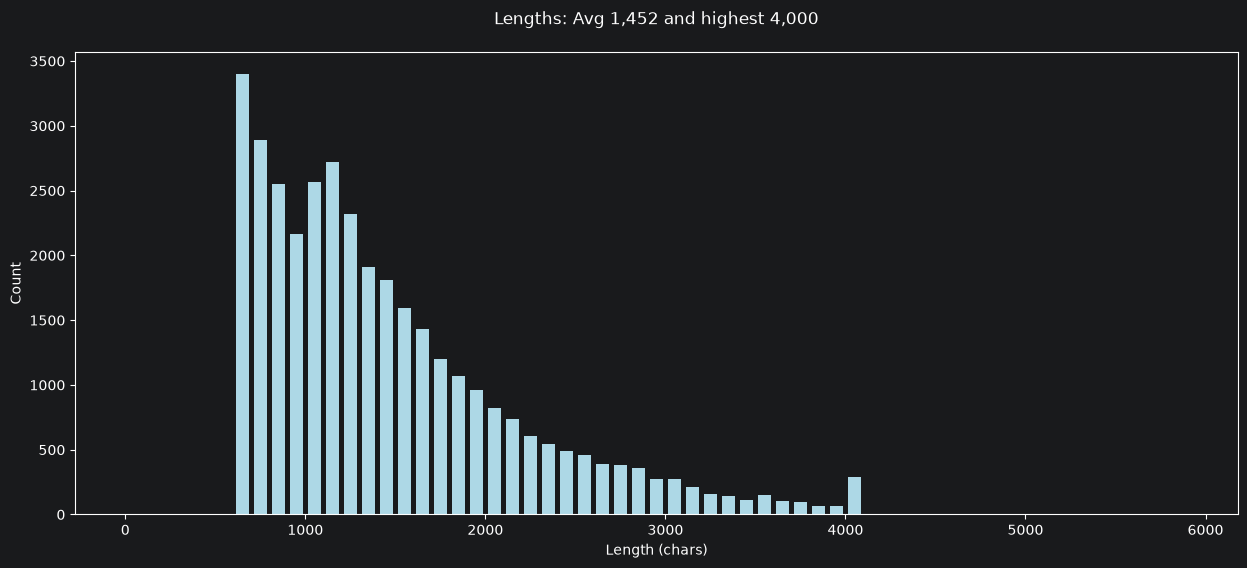

In [6]:
prices = [item.price for item in items]
lengths = [len(item.full) for item in items]

# Plot the distribution of lengths

plt.figure(figsize=(15, 6))
plt.title(f"Lengths: Avg {sum(lengths)/len(lengths):,.0f} and highest {max(lengths):,}\n")
plt.xlabel('Length (chars)')
plt.ylabel('Count')
plt.hist(lengths, rwidth=0.7, color="lightblue", bins=range(0, 6000, 100))
plt.show()

In [7]:
max_length = max(lengths)
max_length_item = items[lengths.index(max_length)]
print(max_length_item.full)

Polyester Dryer Vent Filters Replacement Part by Beaquicy Replacement for Better vent Indoor Dryer Vent Packs of 12
['✅【 AIR 】--- The polyester filters provide optimal air conditioning for your dryer and keep it away from polluted air. Because these parts will rate to trap fine lint and dust particles, protect your home from unwanted bacteria and other unfriendly dust particles and can be vacuumed clean or replaced when fully loaded with lint. so that the air in your room is cleaner than ever. While protecting your indoor quality, clothes can dry faster. It helps improve the indoor air quality.', '✅【HIGH-GRADE 】--- The package includes 12 x replacement polyester filters for bettervent.They are well-made from durable and high-grade polyester which can traps fine lint and dust particles, optimize the cleaning process and prolong lifetime. Each filter protects up to 5 dryer loads! For best results insert blue side facing towards dryer vent.', '✅【WIDE 】--- These polyester filters are desig

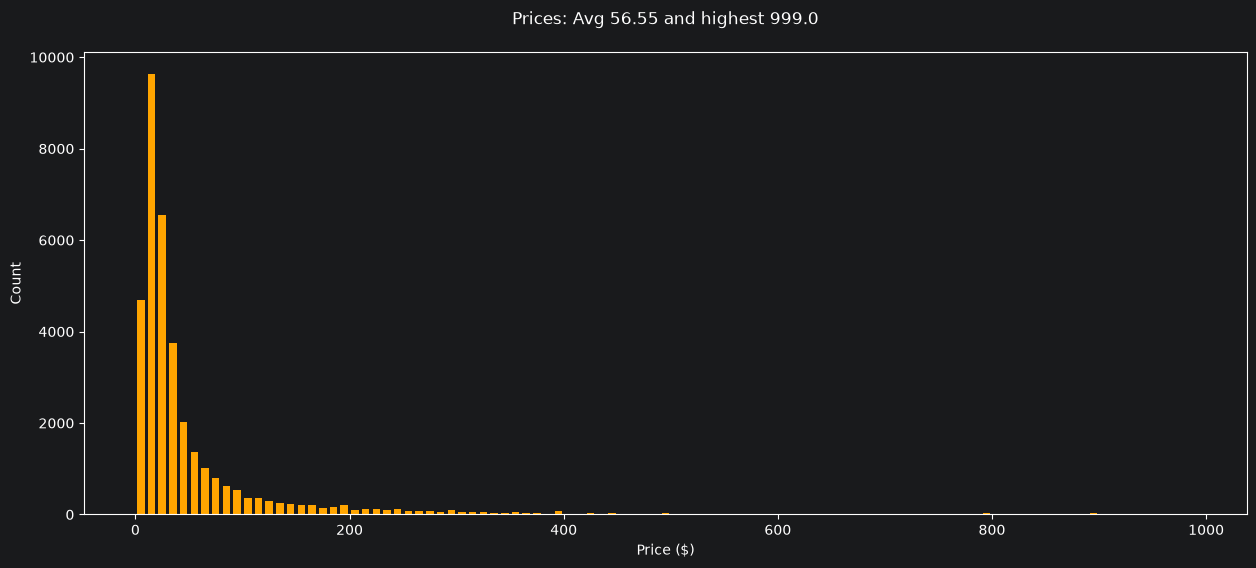

In [8]:
# Plot the distribution of prices
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.2f} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="orange", bins=range(0, 1000, 10))
plt.show()

In [9]:
print(items[3].full)

MLGB Stainless Steel Brushed Pattern Dishwasher Magnet Cover Panel Decal Home Appliance Art, Stainless Steel Fridge Door Cover Decals Magnetic, Black, Mobile Magnetic 23" x 26"
['Stainless Steel Brushed Pattern Magnetic Dishwasher Panel Covers allow you to easily transform your kitchen as the seasons change. You can instantly get rid of outdated and/or mismatched appliances, will give your kitchen a refreshing look.', ':', 'Vinyl + rubber magnet', 'Occasion:', 'Magnet Dishwasher Cover Decor dishwasher covers and any metal device surface with magnetism.', '【Kitchen Dishwasher Covers SIZE】S - 23 W x 17 H inches; 58.5 W x 43 H cm;L - 23 W x 26 H inches; 58.5 W x 66 H cm;', 'Attention:', 'Just ensure that your dishwasher is magnetic before ordering the dishwasher cover magnet', 'Due to the inconsistent calibration of the monitor, the colors on the computer monitor may be slightly different.', 'Quality service:', 'If you have any questions or questions, please feel free to contact us and we

In [10]:
from pricer.data.loaders import ItemLoader

# Process each category sequentially so only one large source dataset is open at a time.
# ItemLoader parallelizes the CPU-heavy parsing *within* each category.
dataset_names = [
    "Automotive",
    "Electronics",
    "Office_Products",
    "Tools_and_Home_Improvement",
    "Cell_Phones_and_Accessories",
    "Toys_and_Games",
    "Appliances",
    "Musical_Instruments",
]
# Accumulate only the compact, validated Item objects returned by each loader.
items = []
for category_number, dataset_name in enumerate(dataset_names, start=1):
    # This category-level status complements ItemLoader's per-chunk progress bar.
    print(f"\n[{category_number}/{len(dataset_names)}] Starting {dataset_name}", flush=True)
    loader = ItemLoader(dataset_name)
    # workers=None (the default) lets the loader adapt to CPU, RAM, and dataset size.
    items.extend(loader.load())
    print(f"  Overall: {category_number}/{len(dataset_names)} categories complete; {len(items):,} items collected", flush=True)
print(f"A grand total of {len(items):,} items")
items[1000]


[1/8] Starting Automotive
  Phase 1/2: Downloading or opening cached Automotive data...


Generating train split: 0 examples [00:00, ? examples/s]

KeyboardInterrupt: 

In [ ]:
random.seed(42)
random.shuffle(items)

seen = set()
items = [x for x in tqdm(items) if not (x.title in seen or seen.add(x.title))]

seen = set()
items = [x for x in tqdm(items) if not (x.full in seen or seen.add(x.full))]

del seen
print(f"After deduplication, we have {len(items):,} items")

In [ ]:
lengths = [len(item.full) for item in items]
plt.figure(figsize=(15, 6))
plt.title(f"Text length: Avg {sum(lengths)/len(lengths):,.1f} and highest {max(lengths):,}\n")
plt.xlabel('Length (characters)')
plt.ylabel('Count')
plt.hist(lengths, rwidth=0.7, color="skyblue", bins=range(0, 4050, 50))
plt.show()

In [ ]:
# Plot the distribution of prices

prices = [item.price for item in items]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

In [ ]:
from collections import Counter
category_counts = Counter([item.category for item in items])

categories = category_counts.keys()
counts = [category_counts[category] for category in categories]

plt.figure(figsize=(15, 6))
plt.bar(categories, counts, color="goldenrod")
plt.title('How many in each category')
plt.xlabel('Categories')
plt.ylabel('Count')
plt.xticks(rotation=30, ha='right')

for i, v in enumerate(counts):
    plt.text(i, v, f"{v:,}", ha='center', va='bottom')

plt.show()

In [ ]:
np.random.seed(42)

SIZE = 820_000

prices = np.array([it.price for it in items], dtype=float)
categories = np.array([it.category for it in items])
p = (prices - prices.min()) / (prices.max() - prices.min() + 1e-9)

w = p**2
w[categories == "Tools_and_Home_Improvement"] *= 0.5
w[categories == "Automotive"] *= 0.05

w = w / w.sum()
idx = np.random.choice(len(items), size=SIZE, replace=False, p=w)
sample = [items[i] for i in idx]
prices = [item.price for item in sample]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} lowest {min(prices):,} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

In [ ]:
# Just for good measure, let's shuffle the sample again for the final dataset

random.seed(42)
random.shuffle(sample)
prices = [item.price for item in sample]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} lowest {min(prices):,} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

In [ ]:
from collections import Counter
category_counts = Counter([item.category for item in sample])

categories = category_counts.keys()
counts = [category_counts[category] for category in categories]

# Bar chart by category
plt.figure(figsize=(15, 6))
plt.bar(categories, counts, color="goldenrod")
plt.title('How many in each category')
plt.xlabel('Categories')
plt.ylabel('Count')

plt.xticks(rotation=30, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(counts):
    plt.text(i, v, f"{v:,}", ha='center', va='bottom')

# Display the chart
plt.show()

In [ ]:
# Automotive still in the lead, but improved somewhat
# For another perspective, let's look at a pie

plt.figure(figsize=(12, 10))
plt.pie(counts, labels=categories, autopct='%1.0f%%', startangle=90)

# Add a circle at the center to create a donut chart (optional)
# centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
# fig.gca().add_artist(centre_circle)
plt.title('Categories')

# Equal aspect ratio ensures that pie is drawn as a circle
plt.axis('equal')

plt.show()

In [ ]:
# How does the price vary with the character count?

sizes = [len(item.full) for item in sample]
prices = [item.price for item in sample]

# Create the scatter plot
plt.figure(figsize=(15, 8))
plt.scatter(sizes, prices, s=0.2, color="red")

# Add labels and title
plt.xlabel('Size')
plt.ylabel('Price')
plt.title('Is there a simple correlation with text length?')

# Display the plot
plt.show()

In [ ]:
# How does the price vary with the weight?

ounces = [item.weight for item in sample]
prices = [item.price for item in sample]

# Create the scatter plot
plt.figure(figsize=(15, 8))
plt.scatter(ounces, prices, s=0.2, color="darkorange")

# Add labels and title
plt.xlabel('Weight (ounces)')
plt.ylabel('Price')
plt.xlim(0, 400)
plt.title('Is there a simple correlation with weight?')

# Display the plot
plt.show()

In [ ]:
username = "akshaymgupte87"
full = f"{username}/items_raw_full"
lite = f"{username}/items_raw_lite"

train = sample[:800_000]
val = sample[800_000:810_000]
test = sample[810_000:]

Item.push_to_hub(full, train, val, test)

train_lite = train[:20_000]
val_lite = val[:1_000]
test_lite = test[:1_000]

Item.push_to_hub(lite, train_lite, val_lite, test_lite)

In [ ]:
### Completely independent of above since dataset is already on HuggingFace Hub. This section is just to demonstrate how to load it back in and run a local model on it.

In [ ]:
from dotenv import load_dotenv
import json
from pricer.data.batch import Batch
from pricer.data.items import Item

load_dotenv(override=True)

In [ ]:
LITE_MODE = False
username = "akshaymgupte87"
dataset = f"{username}/items_raw_lite" if LITE_MODE else f"{username}/items_raw_full"

train, val, test = Item.from_hub(dataset)

items = train + val + test

print(f"Loaded {len(items):,} items")
print(items[0])

In [ ]:
items[2].id

In [ ]:
# Give every item an id

for index, item in enumerate(items):
    item.id = index

In [ ]:
# Reload the local module so this notebook sees edits made to src/pricer/data/batch.py
# without requiring a complete kernel restart.
import importlib
import pricer.data.batch as batch_module

batch_module = importlib.reload(batch_module)
Batch = batch_module.Batch
MODEL = batch_module.MODEL
OLLAMA_HOST = batch_module.OLLAMA_HOST
SYSTEM_PROMPT = batch_module.SYSTEM_PROMPT
ollama_chat_response = batch_module.ollama_chat_response

# Use the same local Qwen model and prompt configuration as the batch pipeline.
print(items[0].full)
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": items[0].full},
]
response = ollama_chat_response(messages)
summary = response["message"]["content"].strip()
items[0].summary = summary

print(f"\nLocal model: {MODEL}")
print(f"Ollama host: {OLLAMA_HOST}")
print(summary)
print(f"\nInput tokens: {response.get('prompt_eval_count', 0):,}")
print(f"Output tokens: {response.get('eval_count', 0):,}")
print("Cost: $0.00 (local inference)")


In [ ]:
def make_jsonl(item):
    # Ollama runs locally and does not use OpenAI/Groq batch endpoints.
    # Store each prompt in the same simple format used by pricer.batch.
    line = {
        "custom_id": str(item.id),
        "model": MODEL,
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": item.full},
        ],
    }
    return json.dumps(line, ensure_ascii=False)
items[0]

In [ ]:
make_jsonl(items[0])

In [ ]:
from pathlib import Path

def make_file(start, end, filename):
    batch_file = Path(filename)
    # Create jsonl/ (or any other parent folder) before opening the file.
    batch_file.parent.mkdir(parents=True, exist_ok=True)
    safe_end = min(end, len(items))
    with batch_file.open("w", encoding="utf-8") as f:
        for i in range(start, safe_end):
            f.write(make_jsonl(items[i]))
            f.write("\n")
    print(f"Wrote {safe_end - start:,} local Qwen requests to {batch_file.resolve()}")
make_file(0, 1000, "../jsonl/0_1000.jsonl")

In [ ]:
# Run the first saved request locally with qwen3.6:latest.
with open("../jsonl/0_1000.jsonl", encoding="utf-8") as f:
    request = json.loads(next(f))

assert request["model"] == "qwen3.6:latest"
response = ollama_chat_response(request["messages"])
response

In [ ]:
# Process the JSONL requests locally with qwen3.6:latest through Ollama.
from pathlib import Path

batch_module.MODEL = "qwen3.6:latest"
MODEL = batch_module.MODEL
requests_file = Path("../jsonl/0_1000.jsonl")
results_file = Path("../jsonl/batch_results.jsonl")

completed_ids = set()
if results_file.exists():
    with results_file.open(encoding="utf-8") as f:
        for line in f:
            try:
                completed_ids.add(str(json.loads(line)["custom_id"]))
            except (json.JSONDecodeError, KeyError):
                pass

with requests_file.open(encoding="utf-8") as requests, results_file.open("a", encoding="utf-8") as results:
    for line in tqdm(requests, desc="Running qwen3.6:latest locally", unit="item"):
        request = json.loads(line)
        custom_id = str(request["custom_id"])
        if custom_id in completed_ids:
            continue

        response = ollama_chat_response(request["messages"])
        summary = response["message"]["content"].strip()
        result = {"custom_id": custom_id, "summary": summary}
        results.write(json.dumps(result, ensure_ascii=False) + "\n")
        results.flush()
        items[int(custom_id)].summary = summary
        completed_ids.add(custom_id)

print(f"Completed {len(completed_ids):,} summaries with qwen3.6:latest")
print(items[0].summary)

In [ ]:
Batch.create(items, LITE_MODE)
Batch.run(workers=4)
Batch.fetch()
for index, item in enumerate(items):
    if not item.summary:
        print(index)
print(items[10234].summary)
# Remove the fields that we don't need in the hub

for item in items:
    item.full = None
    item.id = None

In [ ]:
username = "akshaymgupte87"
full = f"{username}/items_full"
lite = f"{username}/items_lite"

if LITE_MODE:
    train = items[:20_000]
    val = items[20_000:21_000]
    test = items[21_000:]
    Item.push_to_hub(lite, train, val, test)
else:
    train = items[:800_000]
    val = items[800_000:810_000]
    test = items[810_000:]
    Item.push_to_hub(full, train, val, test)

    train_lite = train[:20_000]
    val_lite = val[:1_000]
    test_lite = test[:1_000]
    Item.push_to_hub(lite, train_lite, val_lite, test_lite)

In [ ]:
import random
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.ensemble import RandomForestRegressor
from pricer.evaluation.evaluator import evaluate
from pricer.data.items import Item

In [ ]:
LITE_MODE = False
##Taking it from others for now to avoid delay to process all records locally and push to huggingface.
# Will push to my own space later. This is the next independent cell to start from.
#Checkpoint 2
username = "ed-donner"
dataset = f"{username}/items_lite" if LITE_MODE else f"{username}/items_full"

train, val, test = Item.from_hub(dataset)

print(f"Loaded {len(train):,} training items, {len(val):,} validation items, {len(test):,} test items")

In [ ]:
def random_pricer(item):
    return random.randrange(1,1000)
random.seed(42)
evaluate(random_pricer, test)

# That was fun!
# We can do better - here's another rather trivial model

training_prices = [item.price for item in train]
training_average = sum(training_prices) / len(training_prices)
print(training_average)

def constant_pricer(item):
    return training_average

evaluate(constant_pricer, test)

def get_features(item):
    return {
        "weight": item.weight,
        "weight_unknown": 1 if item.weight==0 else 0,
        "text_length": len(item.summary)
    }

def list_to_dataframe(items):
    features = [get_features(item) for item in items]
    df = pd.DataFrame(features)
    df['price'] = [item.price for item in items]
    return df

train_df = list_to_dataframe(train)
test_df = list_to_dataframe(test)

In [ ]:
# Traditional Linear Regression!

np.random.seed(42)

# Separate features and target
feature_columns = ['weight', 'weight_unknown', 'text_length']

X_train = train_df[feature_columns]
y_train = train_df['price']
X_test = test_df[feature_columns]
y_test = test_df['price']

# Train a Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

for feature, coef in zip(feature_columns, model.coef_):
    print(f"{feature}: {coef}")
print(f"Intercept: {model.intercept_}")

# Predict the test set and evaluate
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R-squared Score: {r2}")

def linear_regression_pricer(item):
    features = get_features(item)
    features_df = pd.DataFrame([features])
    return model.predict(features_df)[0]

evaluate(linear_regression_pricer, test)
prices = np.array([float(item.price) for item in train])
documents = [item.summary for item in train]
np.random.seed(42)
vectorizer = CountVectorizer(max_features=2000, stop_words='english')
X = vectorizer.fit_transform(documents)
# Here are the 1,000 most common words that it picked, not including "stop words":

selected_words = vectorizer.get_feature_names_out()
print(f"Number of selected words: {len(selected_words)}")
print("Selected words:", selected_words[1000:1020])
regressor = LinearRegression()
regressor.fit(X, prices)

def natural_language_linear_regression_pricer(item):
    x = vectorizer.transform([item.summary])
    return max(regressor.predict(x)[0], 0)

evaluate(natural_language_linear_regression_pricer, test)
subset = 15_000
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=4)
rf_model.fit(X[:subset], prices[:subset])

In [ ]:
def random_forest(item):
    x = vectorizer.transform([item.summary])
    return max(0, rf_model.predict(x)[0])
evaluate(random_forest, test)
# This is how to save the model if you want to, particularly if you run this on a larger dataset

# import joblib
# joblib.dump(rf_model, "random_forest.joblib")

In [ ]:
import xgboost as xgb
np.random.seed(42)

xgb_model = xgb.XGBRegressor(n_estimators=1000, random_state=42, n_jobs=4, learning_rate=0.1)
xgb_model.fit(X, prices)

def xg_boost(item):
    x = vectorizer.transform([item.summary])
    return max(0, xgb_model.predict(x)[0])

evaluate(xg_boost, test)

In [ ]:
# Train a Random Forest on the complete training dataset.
# This can take many hours for the 800,000-item full dataset.
from sklearn.ensemble import RandomForestRegressor

if X.shape[0] != len(prices):
    raise ValueError("X and prices must contain the same number of training rows")

full_rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
full_rf_model.fit(X, prices)

def full_random_forest_pricer(item):
    item_text = item.summary or ""
    item_features = vectorizer.transform([item_text])
    prediction = full_rf_model.predict(item_features)[0]
    return float(np.clip(prediction, 0, 1000))

evaluate(full_random_forest_pricer, test)

# Optional: save the trained model and its matching vectorizer.
# import joblib
# joblib.dump({"model": full_rf_model, "vectorizer": vectorizer}, "full_random_forest.joblib")

In [ ]:
### Starting new section


In [ ]:
# imports

import os
from dotenv import load_dotenv
from huggingface_hub import login
from pricer.evaluation.evaluator import evaluate
from litellm import completion
from pricer.data.items import Item
import numpy as np
from tqdm.notebook import tqdm
import csv
from sklearn.feature_extraction.text import HashingVectorizer
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from torch.optim.lr_scheduler import CosineAnnealingLR
LITE_MODE = False

load_dotenv(override=True)
hf_token = os.environ['HF_TOKEN']
login(hf_token, add_to_git_credential=True)
username = "ed-donner"
dataset = f"{username}/items_lite" if LITE_MODE else f"{username}/items_full"

train, val, test = Item.from_hub(dataset)

print(f"Loaded {len(train):,} training items, {len(val):,} validation items, {len(test):,} test items")

In [ ]:
# Write the test set to a CSV

with open('../human_in.csv', 'w', encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    for t in test[:100]:
        writer.writerow([t.summary, 0])
# Read it back in

human_predictions = []
with open('../human_out.csv', 'r', encoding="utf-8") as csvfile:
    reader = csv.reader(csvfile)
    for row in reader:
        human_predictions.append(float(row[1]))
def human_pricer(item):
    idx = test.index(item)
    return human_predictions[idx]
human = human_pricer(test[0])
actual = test[0].price
print(f"Human predicted {human} for an item that actually costs {actual}")
evaluate(human_pricer, test, size=100)

In [ ]:
# Prepare our documents and prices

y = np.array([float(item.price) for item in train])
documents = [item.summary for item in train]
# Use the HashingVectorizer for a Bag of Words model
# Using binary=True with the CountVectorizer makes "one-hot vectors"

np.random.seed(42)
vectorizer = HashingVectorizer(n_features=5000, stop_words='english', binary=True)
X = vectorizer.fit_transform(documents)
# Define the neural network - here is Pytorch code to create a 8 layer neural network

class NeuralNetwork(nn.Module):
    def __init__(self, input_size):
        super(NeuralNetwork, self).__init__()
        self.layer1 = nn.Linear(input_size, 128)
        self.layer2 = nn.Linear(128, 64)
        self.layer3 = nn.Linear(64, 64)
        self.layer4 = nn.Linear(64, 64)
        self.layer5 = nn.Linear(64, 64)
        self.layer6 = nn.Linear(64, 64)
        self.layer7 = nn.Linear(64, 64)
        self.layer8 = nn.Linear(64, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        output1 = self.relu(self.layer1(x))
        output2 = self.relu(self.layer2(output1))
        output3 = self.relu(self.layer3(output2))
        output4 = self.relu(self.layer4(output3))
        output5 = self.relu(self.layer5(output4))
        output6 = self.relu(self.layer6(output5))
        output7 = self.relu(self.layer7(output6))
        output8 = self.layer8(output7)
        return output8
# Convert data to PyTorch tensors
X_train_tensor = torch.FloatTensor(X.toarray())
y_train_tensor = torch.FloatTensor(y).unsqueeze(1)

# Split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_train_tensor, y_train_tensor, test_size=0.01, random_state=42)

# Create the loader
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# Initialize the model
input_size = X_train_tensor.shape[1]
model = NeuralNetwork(input_size)
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Number of trainable parameters: {trainable_params:,}")
# Define loss function and optimizer

loss_function = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# We will do 2 complete runs through the data

EPOCHS = 2

for epoch in range(EPOCHS):
    model.train()
    for batch_X, batch_y in tqdm(train_loader):
        optimizer.zero_grad()

        # The next 4 lines are the 4 stages of training: forward pass, loss calculation, backward pass, optimize

        outputs = model(batch_X)
        loss = loss_function(outputs, batch_y)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val)
        val_loss = loss_function(val_outputs, y_val)

    print(f'Epoch [{epoch+1}/{EPOCHS}], Train Loss: {loss.item():.3f}, Val Loss: {val_loss.item():.3f}')

def neural_network(item):
    model.eval()
    with torch.no_grad():
        vector = vectorizer.transform([item.summary])
        vector = torch.FloatTensor(vector.toarray())
        result = model(vector)[0].item()
    return max(0, result)
evaluate(neural_network, test)

In [ ]:
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

LOCAL_QWEN_MODEL = "qwen3.6:latest"
LOCAL_OLLAMA_HOST = os.environ.get("OLLAMA_HOST", "http://127.0.0.1:11434").rstrip("/")
if not LOCAL_OLLAMA_HOST.startswith(("http://", "https://")):
    LOCAL_OLLAMA_HOST = f"http://{LOCAL_OLLAMA_HOST}"

def build_price_estimation_messages(item):
    prompt = f"Estimate the price of this product. Respond with the price only, no explanation.\n\n{item.summary}"
    return [{"role": "user", "content": prompt}]

def call_local_qwen(messages):
    payload = {
        "model": LOCAL_QWEN_MODEL,
        "messages": messages,
        "stream": False,
        "think": False,
        "keep_alive": "30m",
        "options": {"temperature": 0, "num_predict": 20, "seed": 42},
    }
    request = Request(
        f"{LOCAL_OLLAMA_HOST}/api/chat",
        data=json.dumps(payload).encode("utf-8"),
        headers={"Content-Type": "application/json"},
        method="POST",
    )
    try:
        with urlopen(request, timeout=300) as response:
            result = json.load(response)
    except HTTPError as exc:
        detail = exc.read().decode("utf-8", errors="replace")
        raise RuntimeError(f"Ollama returned HTTP {exc.code}: {detail}") from exc
    except URLError as exc:
        raise RuntimeError(f"Cannot reach Ollama at {LOCAL_OLLAMA_HOST}. Start Ollama first.") from exc
    return result["message"]["content"].strip()

def local_qwen_3_6_pricer(item):
    return call_local_qwen(build_price_estimation_messages(item))

print(test[0].summary)
print(f"Local Qwen prediction: {local_qwen_3_6_pricer(test[0])}")
print(f"Actual price: ${test[0].price:,.2f}")
evaluate(local_qwen_3_6_pricer, test, workers=1)

# Hosted frontier-model examples are retained for reference but disabled.
# def gpt_4_1_nano_pricer(item):
#     response = completion(model="openai/gpt-4.1-nano", messages=build_price_estimation_messages(item))
#     return response.choices[0].message.content
# evaluate(gpt_4_1_nano_pricer, test)

# def claude_opus_4_5_pricer(item):
#     response = completion(model="anthropic/claude-opus-4-5", messages=build_price_estimation_messages(item))
#     return response.choices[0].message.content
# evaluate(claude_opus_4_5_pricer, test)

# def gemini_3_pro_preview_pricer(item):
#     response = completion(model="gemini/gemini-3-pro-preview", messages=build_price_estimation_messages(item), reasoning_effort="low")
#     return response.choices[0].message.content
# evaluate(gemini_3_pro_preview_pricer, test, size=50, workers=2)

# def gemini_3_1_flash_lite_pricer(item):
#     response = completion(model="gemini/gemini-3.1-flash-lite", messages=build_price_estimation_messages(item))
#     return response.choices[0].message.content
# evaluate(gemini_3_1_flash_lite_pricer, test)

# def grok_4_1_fast_pricer(item):
#     response = completion(model="xai/grok-4-1-fast-non-reasoning", messages=build_price_estimation_messages(item), seed=42)
#     return response.choices[0].message.content
# evaluate(grok_4_1_fast_pricer, test)

# def gpt_5_1_pricer(item):
#     response = completion(model="gpt-5.1", messages=build_price_estimation_messages(item), reasoning_effort="high", seed=42)
#     return response.choices[0].message.content
# evaluate(gpt_5_1_pricer, test)

In [ ]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
# Local Ollama evaluation only -- no Hugging Face model download and no fine-tuning.

import numpy as np

from pricer.evaluation.evaluator import Tester

OLLAMA_EVALUATION_ITEMS = 20000

if "test" not in globals():
    raise RuntimeError("Run the dataset-loading cell before this evaluation cell.")
if "local_qwen_3_6_pricer" not in globals():
    raise RuntimeError("Run the preceding local Ollama Qwen cell first.")

evaluation_size = min(OLLAMA_EVALUATION_ITEMS, len(test))
print(f"Evaluating installed Ollama model qwen3.6:latest on {evaluation_size:,} held-out items...")
ollama_qwen_tester = Tester(
    local_qwen_3_6_pricer,
    test,
    title="Local Ollama qwen3.6:latest (no fine-tuning)",
    size=evaluation_size,
    workers=1,
)
ollama_qwen_tester.run()
ollama_qwen_mae = float(np.mean(ollama_qwen_tester.errors))

reference_results = {
    "OpenAI mini, 200 fine-tuning examples": 96.58,
    "OpenAI mini, 2,000 fine-tuning examples": 79.29,
    "OpenAI nano, 2,000 fine-tuning examples": 82.26,
    "OpenAI nano, 20,000 fine-tuning examples": 67.75,
    "Local Ollama qwen3.6:latest, 2000 fine tuning examples no fine-tuning: $57.33 MAE"
    "Local Ollama qwen3.6:latest, no fine-tuning": ollama_qwen_mae,
}
print("\n# Historical-reference comparison (lower MAE is better)")
print(f"# Local Qwen was evaluated on {evaluation_size:,} held-out items through Ollama.")
print("# No adapter was trained and no Hugging Face model weights were downloaded.")
for label, mae in sorted(reference_results.items(), key=lambda result: result[1]):
    print(f"# {label}: ${mae:,.2f} MAE")

# OpenAI managed fine-tuning remains disabled; the values above are historical references only.
# Local LoRA/QLoRA fine-tuning is intentionally deferred to a future section.

In [ ]:
# imports
### this is for openai . Ignored for now
import os
import re
import json
from dotenv import load_dotenv
from huggingface_hub import login
from openai import OpenAI
from pricer.data.items  import Item
from pricer.evaluation.evaluator import evaluate
# environment

LITE_MODE = False

load_dotenv(override=True)
hf_token = os.environ['HF_TOKEN']
login(hf_token, add_to_git_credential=True)
username = "ed-donner"
dataset = f"{username}/items_lite" if LITE_MODE else f"{username}/items_full"

train, val, test = Item.from_hub(dataset)

print(f"Loaded {len(train):,} training items, {len(val):,} validation items, {len(test):,} test items")
openai = OpenAI()
# Data size
# OpenAI recommends fine-tuning with a small population of 50-100 examples
#
#

# OpenAI recommends fine-tuning with populations of 50-100 examples


fine_tune_train = train[:100]
fine_tune_validation = val[:50]
len(fine_tune_train)
# Step 1
# Prepare our data for fine-tuning in JSONL (JSON Lines) format and upload to OpenAI

def messages_for(item):
    message = f"Estimate the price of this product. Respond with the price, no explanation\n\n{item.summary}"
    return [
        {"role": "user", "content": message},
        {"role": "assistant", "content": f"${item.price:.2f}"}
    ]
messages_for(fine_tune_train[0])
# Convert the items into a list of json objects - a "jsonl" string
# Each row represents a message in the form:
# {"messages" : [{"role": "system", "content": "You estimate prices...


def make_jsonl(items):
    result = ""
    for item in items:
        messages = messages_for(item)
        messages_str = json.dumps(messages)
        result += '{"messages": ' + messages_str +'}\n'
    return result.strip()
print(make_jsonl(train[:3]))
# Convert the items into jsonl and write them to a file

def write_jsonl(items, filename):
    with open(filename, "w") as f:
        jsonl = make_jsonl(items)
        f.write(jsonl)
write_jsonl(fine_tune_train, "jsonl/fine_tune_train.jsonl")
write_jsonl(fine_tune_validation, "jsonl/fine_tune_validation.jsonl")
with open("jsonl/fine_tune_train.jsonl", "rb") as f:
    train_file = openai.files.create(file=f, purpose="fine-tune")
train_file
with open("jsonl/fine_tune_validation.jsonl", "rb") as f:
    validation_file = openai.files.create(file=f, purpose="fine-tune")
validation_file
# https://platform.openai.com/storage/files/
#
# Step 2
# And now time to Fine-tune!
openai.fine_tuning.jobs.create(
    training_file=train_file.id,
    validation_file=validation_file.id,
    model="gpt-4.1-nano-2025-04-14",
    seed=42,
    hyperparameters={"n_epochs": 1, "batch_size": 1},
    suffix="pricer"
)
openai.fine_tuning.jobs.list(limit=1)
job_id = openai.fine_tuning.jobs.list(limit=1).data[0].id
job_id
openai.fine_tuning.jobs.retrieve(job_id)
openai.fine_tuning.jobs.list_events(fine_tuning_job_id=job_id, limit=10).data
# https://platform.openai.com/finetune
#
# Step 3
# Test our fine tuned model

fine_tuned_model_name = openai.fine_tuning.jobs.retrieve(job_id).fine_tuned_model
fine_tuned_model_name
# The prompt

def test_messages_for(item):
    message = f"Estimate the price of this product. Respond with the price, no explanation\n\n{item.summary}"
    return [
        {"role": "user", "content": message},
    ]
# Try this out

test_messages_for(test[0])
# The inference function


def gpt_4__1_nano_fine_tuned(item):
    response = openai.chat.completions.create(
        model=fine_tuned_model_name,
        messages=test_messages_for(item),
        max_tokens=7
    )
    return response.choices[0].message.content
print(test[0].price)
print(gpt_4__1_nano_fine_tuned(test[0]))
evaluate(gpt_4__1_nano_fine_tuned, test)

In [ ]:
#Trying Qlora

In [ ]:
# imports

import os
import re
import math
from tqdm import tqdm
from huggingface_hub import login
import torch
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, TrainingArguments, set_seed
from peft import LoraConfig, PeftModel
from datetime import datetime

In [ ]:
# Constants

BASE_MODEL = "meta-llama/Llama-3.2-3B"
PROJECT_NAME = "price"
RUN_NAME =  f"{datetime.now():%Y-%m-%d_%H.%M.%S}"
PROJECT_RUN_NAME = f"{PROJECT_NAME}-{RUN_NAME}"

LITE_MODE = False

DATA_USER = "ed-donner"
DATASET_NAME = f"{DATA_USER}/items_prompts_lite" if LITE_MODE else f"{DATA_USER}/items_prompts_full"


FINETUNED_MODEL = f"ed-donner/price-2025-11-30_15.10.55-lite"

In [ ]:
# Log in to HuggingFace

hf_token = os.environ['HF_TOKEN']
login(hf_token, add_to_git_credential=True)

In [ ]:
!uv run price_is_right.py